## Initial Spinup Analysis: Raw NLDAS and CM
Analysis of model spinup using raw NLDAS forcings and the CM version of the snow model.

In [1]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from buildforcing.datasets import PNNLSnotel
import os

In [2]:
# Define environment for paths
path_env = 'desktop' # 'desktop' or 'alpine'

In [3]:
# Configure environment
if path_env == 'desktop':
    output_path = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    snotel_path = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
elif path_env == 'alpine':
    output_path = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    snotel_path = r'/projects/ccox1@xsede.org/data/snotel/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [4]:
# Run configuration
snotel_site = 'Quemazon'  #Use the Snotel name
spin_up = '100y'
forcings = 's00000000'
forcing_build = 'v0.4.4'
run_config = 'v0'

In [5]:
# Convert name for output paths
site = snotel_site.replace(' ','').lower()
print(f'Output site: {site}')

Output site: quemazon


Load diagnostics

In [6]:
folder_path = os.path.join(output_path,f'{site}/{site}_spinup_{spin_up}_{forcings}_{forcing_build}/history/')

In [ ]:
# Find the land daily file name in folder and open
land_daily=None
for filename in os.listdir(folder_path):
    if filename.endswith(".land_daily.nc"):
        land_daily = xr.open_dataset(folder_path + filename)
        land_daily
if not land_daily:
    print('Error: no land daily found')

In [8]:
# Find the land month file name in folder and open
land_month=None
for filename in os.listdir(folder_path):
    if filename.endswith(".land_month.nc"):
        land_month = xr.open_dataset(folder_path + filename)
if not land_month:
    print('Error: no land daily found')

In [9]:
land_month

<xarray.Dataset> Size: 4MB
Dimensions:                  (grid_index: 1, time: 1200, nv: 2, lon: 1,
                              lonb: 2, lat: 1, latb: 2, zfull_soil: 20,
                              zhalf_soil: 21, band: 2)
Coordinates:
  * grid_index               (grid_index) float64 8B 0.0
  * time                     (time) object 10kB 1890-10-16 12:00:00 ... 1990-...
  * nv                       (nv) float64 16B 1.0 2.0
  * lon                      (lon) float64 8B -106.4
  * lonb                     (lonb) float64 16B -106.9 -105.9
  * lat                      (lat) float64 8B 35.92
  * latb                     (latb) float64 16B 35.42 36.42
  * zfull_soil               (zfull_soil) float64 160B 0.01 0.04 ... 6.75 8.75
  * zhalf_soil               (zhalf_soil) float64 168B 0.0 0.02 ... 7.5 10.0
  * band                     (band) float64 16B 1.0 2.0
    geolon_t                 (grid_index) float32 4B ...
    geolat_t                 (grid_index) float32 4B ...
Data variables: (12/221)
    soil_ice                 (time, zfull_soil, grid_index) float32 96kB ...
    soil_liq                 (time, zfull_soil, grid_index) float32 96kB ...
    soil_psi                 (time, zfull_soil, grid_index) float32 96kB ...
    soil_T                   (time, zfull_soil, grid_index) float32 96kB ...
    soil_uptk                (time, zfull_soil, grid_index) float32 96kB ...
    albedo_dif               (time, band, grid_index) float32 10kB ...
    ...                       ...
    cwlitt_dmic_C_resp       (time, grid_index) float32 5kB ...
    Ctot                     (time, grid_index) float32 5kB ...
    average_T1               (time) datetime64[ns] 10kB ...
    average_T2               (time) datetime64[ns] 10kB ...
    average_DT               (time) timedelta64[ns] 10kB ...
    time_bnds                (time, nv) object 19kB ...
Attributes:
    filename:          land_month.nc
    title:             
    associated_files:  soil_area: land_static.nc land_area: land_static.nc
    grid_type:         regular
    grid_tile:         N/A

### Output analysis

In [13]:
vegetation_data = land_month[['height','lai']].isel(grid_index=0).to_dataframe()
vegetation_data.index = vegetation_data.index.to_datetimeindex()

# Drop all columns except 'lai' and 'height'
vegetation_data = vegetation_data[['lai', 'height']]

C:\Users\clmbn\AppData\Local\Temp\ipykernel_7620\3021115198.py:2: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  vegetation_data.index = vegetation_data.index.to_datetimeindex()


array([<Axes: >, <Axes: >], dtype=object)

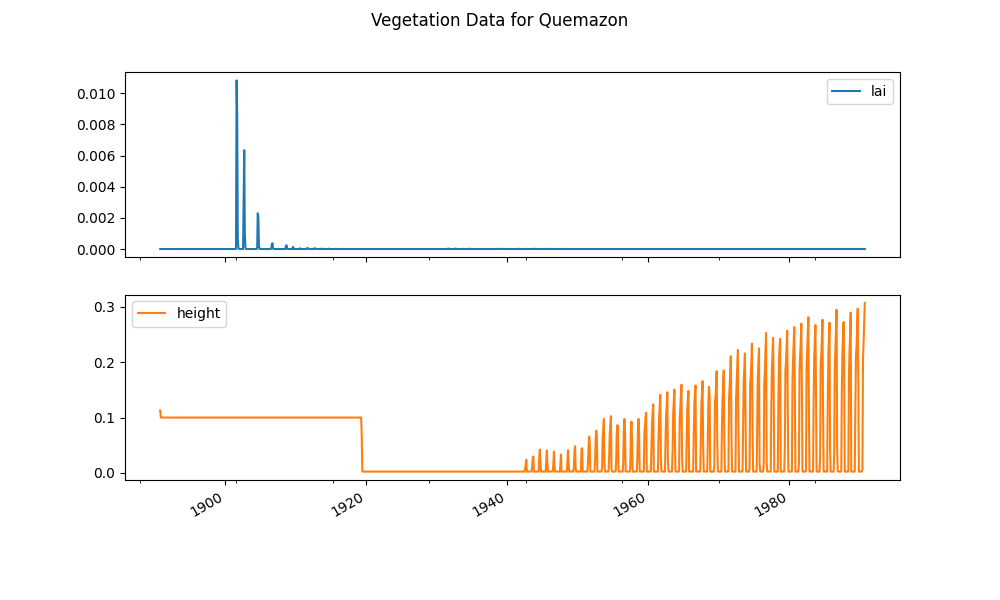

In [14]:
vegetation_data.plot(subplots=True, figsize=(10, 6), title='Vegetation Data for ' + snotel_site)

Soil Data

In [42]:
# Function for extracting soil data
def extract_soil_data(soil_var) -> pd.DataFrame:
    soil_data = land_month[[soil_var]].isel(grid_index=0).to_dataframe()
    soil_data_df = soil_data.reset_index().pivot(index='time', columns='zfull_soil', values=soil_var)
    soil_data_df.columns.name = 'Depth'
    soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
    soil_data_df.columns = [f"{col:03.2f}" for col in soil_data_df.columns]
    return soil_data_df

In [45]:
# Extract the soil data at different depths
soil_T = extract_soil_data('soil_T')
soil_liq = extract_soil_data('soil_liq')
soil_ice = extract_soil_data('soil_ice')

C:\Users\clmbn\AppData\Local\Temp\ipykernel_7620\2036034610.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
C:\Users\clmbn\AppData\Local\Temp\ipykernel_7620\2036034610.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
C:\Users\clmbn\AppData\Local\Temp\ipykernel_7620\2036034610.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses 

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
      dtype=object)

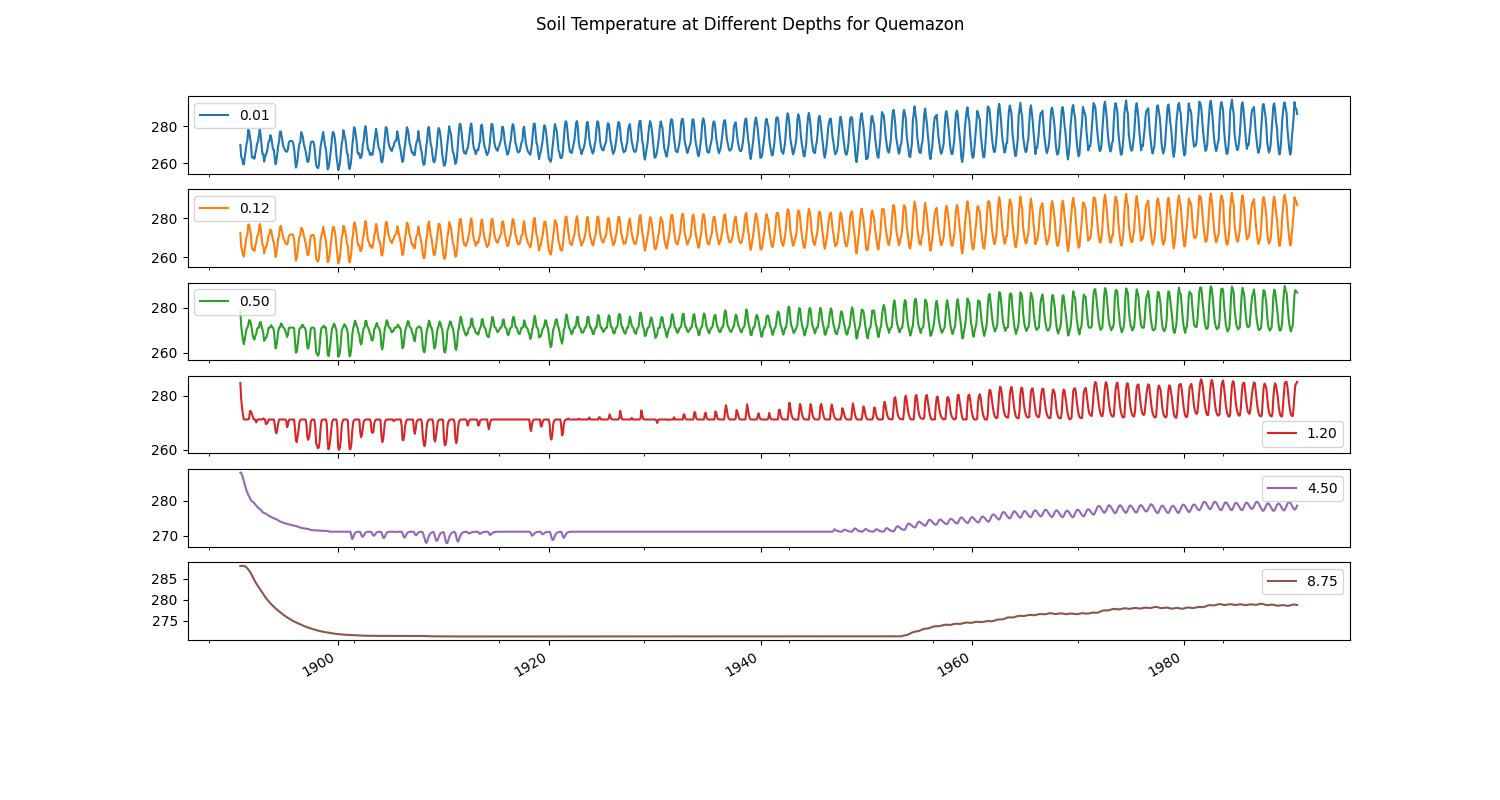

In [44]:
soil_T[['0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Temperature at Different Depths for ' + snotel_site)

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
      dtype=object)

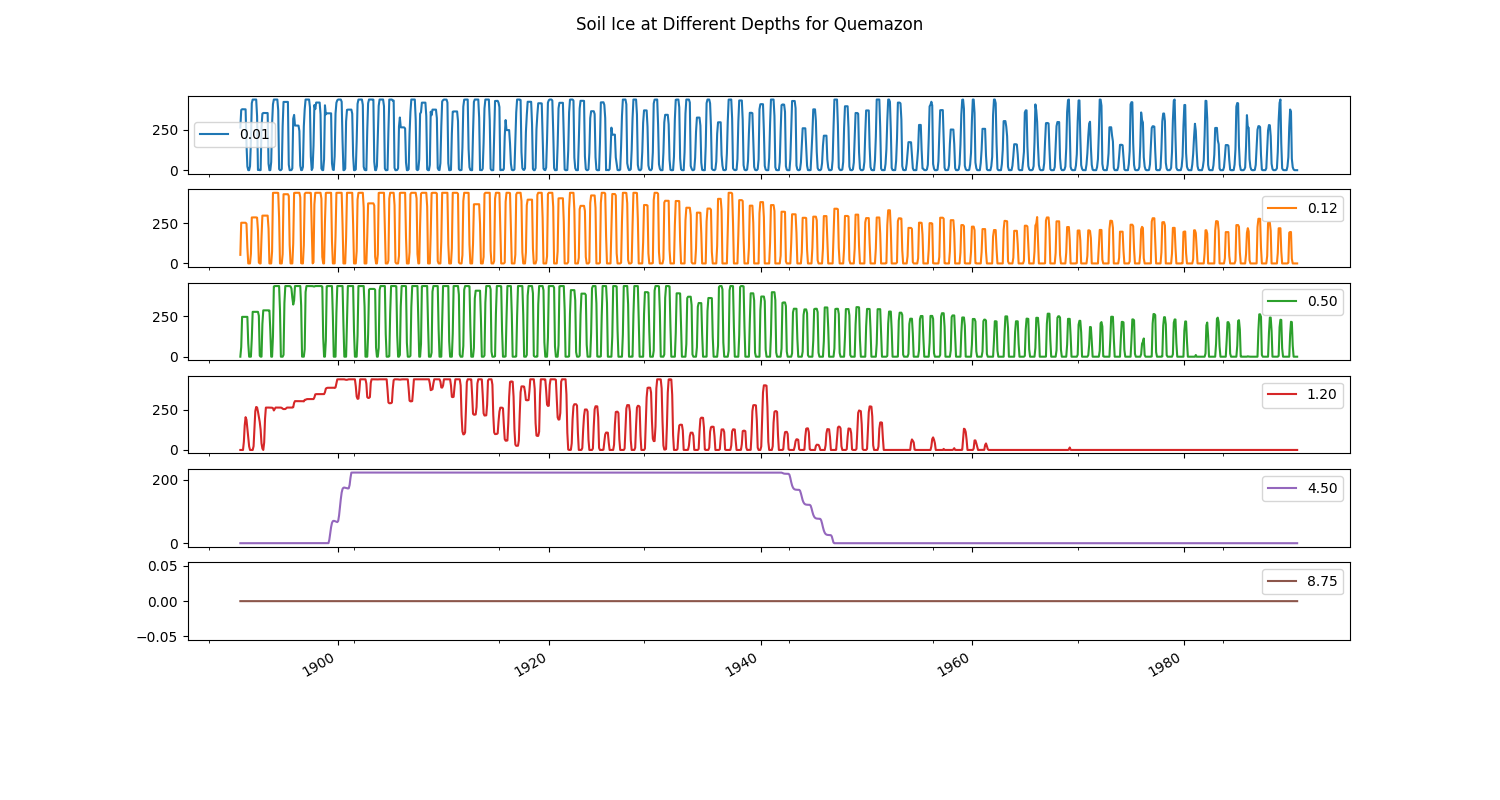

In [46]:
soil_ice[['0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Ice at Different Depths for ' + snotel_site)

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >],
      dtype=object)

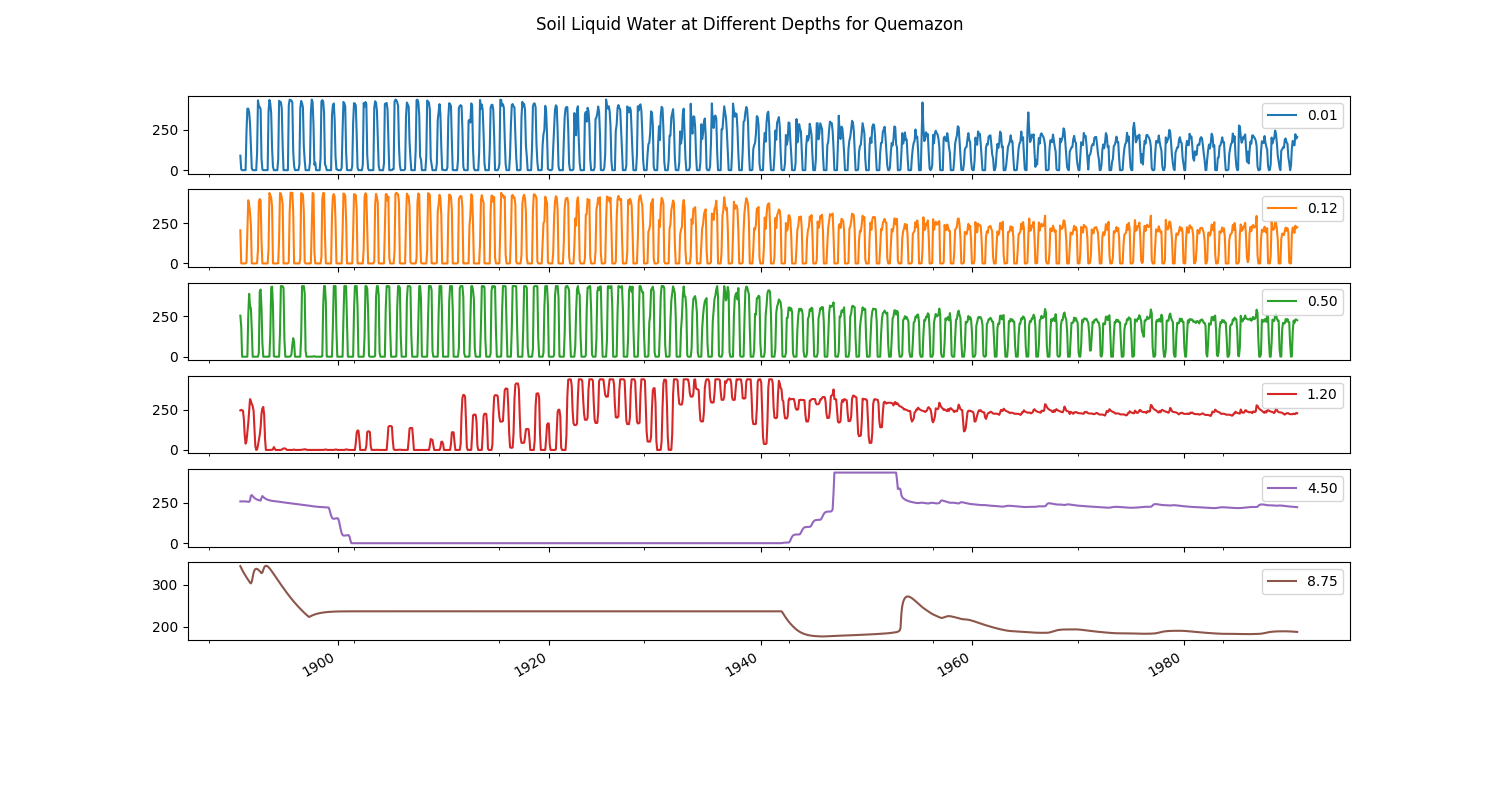

In [47]:
soil_liq[['0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Liquid Water at Different Depths for ' + snotel_site)

Load the Snotel data

In [ ]:
snotel = PNNLSnotel(snotel_site, snotel_path)

In [ ]:
snotel_data = snotel.data

Comparison plots

In [ ]:
fig, axs = plt.subplots(1, 1, figsize=(12, 6))
snow_data['snow'].plot(ax=axs, label='Model Snow Water Equivalent', color='red')
snotel_data['swe_mm'].plot(ax=axs, label='SNOTEL Snow Water Equivalent', color='blue')
axs.legend()
plt.title(f'{snotel_site} nldas cm')

In [ ]:
plt.savefig('quemazon_test.png')